# Chômage au Maroc : quelle tranche d'âge porte la hausse ? (2018-2025)

Projet de data science réalisé à partir des taux de chômage annuels du Haut-Commissariat au Plan (HCP).

**Question de recherche :** depuis 2019, le chômage a nettement augmenté au Maroc. Cette hausse est-elle partagée par tous, ou concentrée sur certains groupes (jeunes, femmes, diplômés, citadins) ?

**Méthode :** statistiques descriptives et visualisation de séries temporelles (variation en points de pourcentage, rapport au taux national, écarts entre groupes).

**Données :** `data/chomage_age_2018_2025.csv` (détail des sources dans `data/SOURCES.md`). Série de l'enquête ENE, qui s'arrête en 2025 : depuis 2026, le HCP utilise une nouvelle enquête (EMO2026) non comparable.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "figure.dpi": 130,
})
BLEU, ORANGE, AQUA, VIOLET, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#52514e"

CHEMIN = Path("data/chomage_age_2018_2025.csv")
if not CHEMIN.exists():
    # Sur Google Colab : importer le fichier CSV depuis votre ordinateur
    from google.colab import files
    files.upload()
    CHEMIN = Path("chomage_age_2018_2025.csv")

df = pd.read_csv(CHEMIN).set_index("annee")
print(df.to_string())

       national  urbain  rural  femmes  hommes  diplomes  age_15_24  age_25_34  age_35_44  age_45_plus  age_25_plus
annee                                                                                                              
2018        9.5    13.8    3.6     NaN     NaN       NaN        NaN        NaN        NaN          NaN          NaN
2019        9.2    12.9    3.7    13.5     7.8      15.7       24.9        NaN        NaN          NaN          7.0
2020       11.9    15.8    5.9    16.2    10.7      18.5       31.2        NaN        NaN          NaN          NaN
2021       12.3    16.9    5.0    16.8    10.9      19.6       31.8        NaN        NaN          NaN          NaN
2022       11.8    15.8    5.2    17.2    10.3      18.6       32.7       19.2        6.4          3.3          NaN
2023       13.0    16.8    6.3    18.3    11.5      19.7       35.8       20.6        7.4          3.7          NaN
2024       13.3    16.9    6.8    19.4    11.6      19.6       36.7     

## 1. Vue d'ensemble : le taux national et les 15-24 ans

Le taux de chômage d'une tranche d'âge est calculé sur les seuls actifs de cette tranche : un taux de 37 % chez les 15-24 ans ne signifie pas que 37 % des jeunes sont au chômage, mais 37 % des jeunes qui travaillent ou cherchent un emploi.

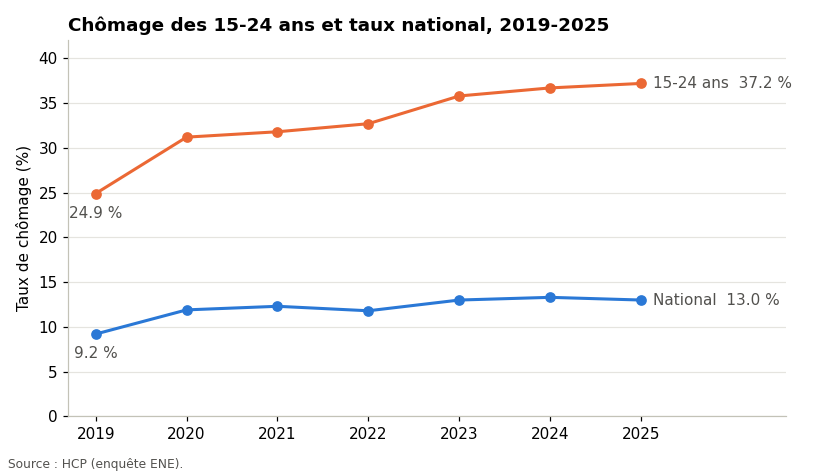

In [2]:
d = df.loc[2019:2025]
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(d.index, d["age_15_24"], marker="o", lw=2, color=ORANGE)
ax.plot(d.index, d["national"], marker="o", lw=2, color=BLEU)
ax.annotate(f"15-24 ans  {d['age_15_24'].iloc[-1]:.1f} %", (2025, d["age_15_24"].iloc[-1]),
            xytext=(8, 0), textcoords="offset points", va="center", color=GRIS)
ax.annotate(f"National  {d['national'].iloc[-1]:.1f} %", (2025, d["national"].iloc[-1]),
            xytext=(8, 0), textcoords="offset points", va="center", color=GRIS)
ax.annotate(f"{d['age_15_24'].iloc[0]:.1f} %", (2019, d["age_15_24"].iloc[0]),
            xytext=(0, -16), textcoords="offset points", ha="center", color=GRIS)
ax.annotate(f"{d['national'].iloc[0]:.1f} %", (2019, d["national"].iloc[0]),
            xytext=(0, -16), textcoords="offset points", ha="center", color=GRIS)
ax.set_xlim(2018.7, 2026.6)
ax.set_ylim(0, 42)
ax.set_xticks(d.index)
ax.set_ylabel("Taux de chômage (%)")
ax.set_title("Chômage des 15-24 ans et taux national, 2019-2025")
ax.grid(axis="y", color="#e5e4df", lw=0.8)
fig.text(0.01, 0.01, "Source : HCP (enquête ENE).", fontsize=8, color=GRIS)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("figures/01_national_vs_jeunes.png")
plt.show()

## 2. Toutes les tranches d'âge (2022-2025)

Le détail par tranche d'âge n'a pas été retrouvé avant 2022 : cette comparaison porte donc sur quatre années.

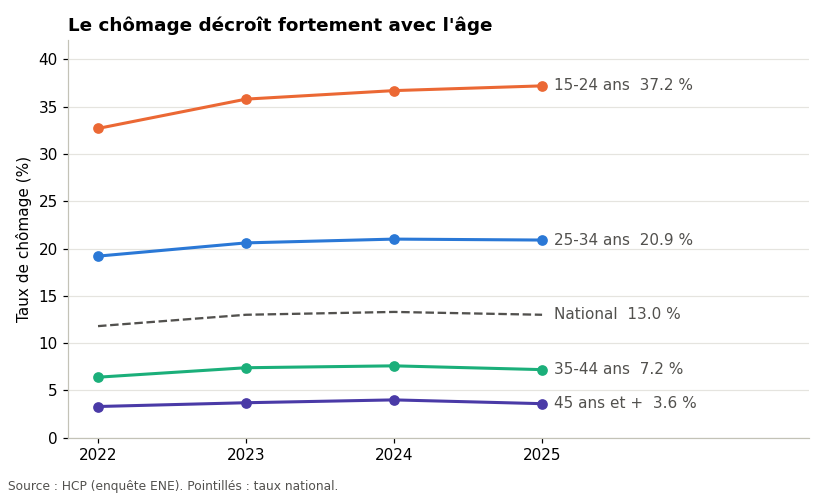

In [3]:
d = df.loc[2022:2025]
series = [
    ("age_15_24", "15-24 ans", ORANGE),
    ("age_25_34", "25-34 ans", BLEU),
    ("age_35_44", "35-44 ans", AQUA),
    ("age_45_plus", "45 ans et +", VIOLET),
]
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for col, label, couleur in series:
    ax.plot(d.index, d[col], marker="o", lw=2, color=couleur)
    ax.annotate(f"{label}  {d[col].iloc[-1]:.1f} %", (2025, d[col].iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", color=GRIS)
ax.plot(d.index, d["national"], lw=1.5, ls="--", color=GRIS)
ax.annotate(f"National  {d['national'].iloc[-1]:.1f} %", (2025, d["national"].iloc[-1]),
            xytext=(8, 0), textcoords="offset points", va="center", color=GRIS)
ax.set_xlim(2021.8, 2026.8)
ax.set_ylim(0, 42)
ax.set_xticks(d.index)
ax.set_ylabel("Taux de chômage (%)")
ax.set_title("Le chômage décroît fortement avec l'âge")
ax.grid(axis="y", color="#e5e4df", lw=0.8)
fig.text(0.01, 0.01, "Source : HCP (enquête ENE). Pointillés : taux national.", fontsize=8, color=GRIS)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("figures/02_tranches_age_2022_2025.png")
plt.show()

## 3. Qui a le plus augmenté depuis 2019 ?

On compare la variation entre 2019 et 2025 en points de pourcentage pour les groupes disponibles sur toute la période.

   groupe  2019  2025  variation_pts  variation_relative_%
15-24 ans  24.9  37.2           12.3                  49.0
   Femmes  13.5  20.5            7.0                  52.0
 National   9.2  13.0            3.8                  41.0
   Urbain  12.9  16.4            3.5                  27.0
 Diplômés  15.7  19.1            3.4                  22.0
   Hommes   7.8  10.8            3.0                  38.0
    Rural   3.7   6.6            2.9                  78.0


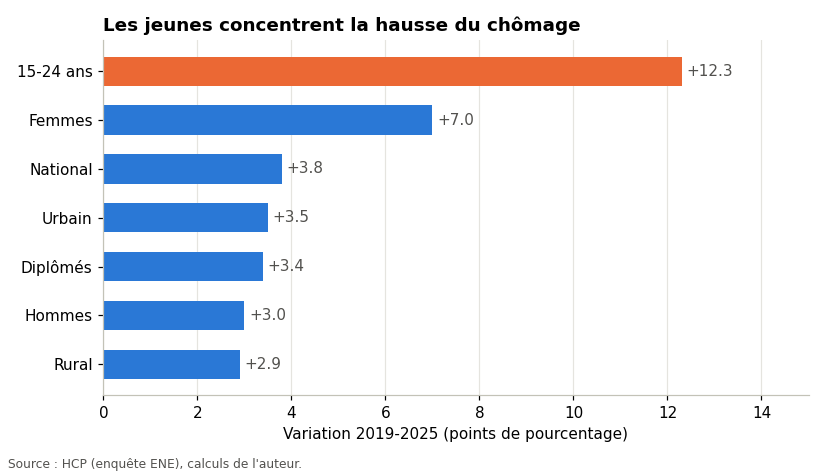

In [4]:
groupes = {
    "national": "National",
    "urbain": "Urbain",
    "rural": "Rural",
    "femmes": "Femmes",
    "hommes": "Hommes",
    "diplomes": "Diplômés",
    "age_15_24": "15-24 ans",
}
var = pd.DataFrame({
    "groupe": list(groupes.values()),
    "2019": [df.loc[2019, c] for c in groupes],
    "2025": [df.loc[2025, c] for c in groupes],
})
var["variation_pts"] = (var["2025"] - var["2019"]).round(1)
var["variation_relative_%"] = ((var["2025"] / var["2019"] - 1) * 100).round(0)
var = var.sort_values("variation_pts", ascending=False)
print(var.to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 4.3))
couleurs = [ORANGE if g == "15-24 ans" else BLEU for g in var["groupe"]]
barres = ax.barh(var["groupe"], var["variation_pts"], color=couleurs, height=0.6)
ax.bar_label(barres, labels=[f"+{v:.1f}" for v in var["variation_pts"]], padding=3, color=GRIS)
ax.invert_yaxis()
ax.set_xlim(0, 15)
ax.set_xlabel("Variation 2019-2025 (points de pourcentage)")
ax.set_title("Les jeunes concentrent la hausse du chômage")
ax.grid(axis="x", color="#e5e4df", lw=0.8)
ax.set_axisbelow(True)
fig.text(0.01, 0.01, "Source : HCP (enquête ENE), calculs de l'auteur.", fontsize=8, color=GRIS)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("figures/03_variation_2019_2025.png")
plt.show()

## 4. Le chômage des jeunes par rapport à la moyenne

Le rapport entre le taux des 15-24 ans et le taux national mesure à quel point les jeunes sont surexposés.

       rapport_jeunes_national  ecart_femmes_hommes_pts  ecart_urbain_rural_pts
annee                                                                          
2019                      2.71                      5.7                     9.2
2020                      2.62                      5.5                     9.9
2021                      2.59                      5.9                    11.9
2022                      2.77                      6.9                    10.6
2023                      2.75                      6.8                    10.5
2024                      2.76                      7.8                    10.1
2025                      2.86                      9.7                     9.8


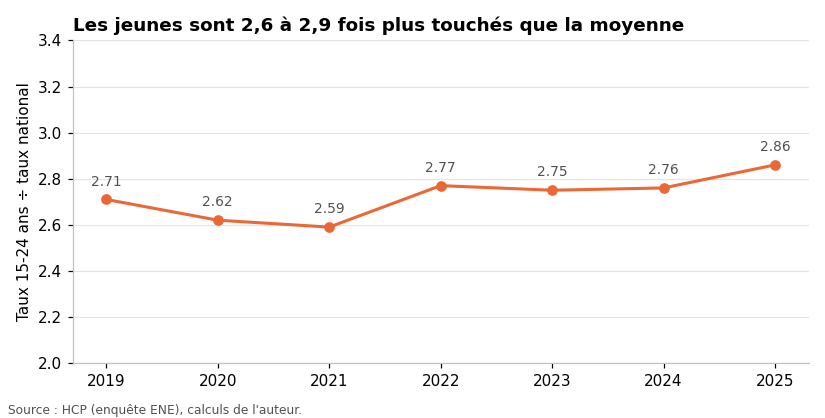

In [5]:
d = df.loc[2019:2025].copy()
d["rapport_jeunes_national"] = (d["age_15_24"] / d["national"]).round(2)
d["ecart_femmes_hommes_pts"] = (d["femmes"] - d["hommes"]).round(1)
d["ecart_urbain_rural_pts"] = (d["urbain"] - d["rural"]).round(1)
print(d[["rapport_jeunes_national", "ecart_femmes_hommes_pts", "ecart_urbain_rural_pts"]].to_string())

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(d.index, d["rapport_jeunes_national"], marker="o", lw=2, color=ORANGE)
for x, y in zip(d.index, d["rapport_jeunes_national"]):
    ax.annotate(f"{y:.2f}", (x, y), xytext=(0, 9), textcoords="offset points", ha="center", color=GRIS, fontsize=9)
ax.set_ylim(2, 3.4)
ax.set_xticks(d.index)
ax.set_ylabel("Taux 15-24 ans ÷ taux national")
ax.set_title("Les jeunes sont 2,6 à 2,9 fois plus touchés que la moyenne")
ax.grid(axis="y", color="#e5e4df", lw=0.8)
fig.text(0.01, 0.01, "Source : HCP (enquête ENE), calculs de l'auteur.", fontsize=8, color=GRIS)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("figures/04_rapport_jeunes_national.png")
plt.show()

## 5. Conclusions

1. **La hausse du chômage depuis 2019 est très inégale.** Le taux national passe de 9,2 % à 13,0 % (+3,8 points), mais celui des 15-24 ans passe de 24,9 % à 37,2 % (+12,3 points), soit la plus forte hausse en points de tous les groupes étudiés (en relatif, le milieu rural progresse davantage, mais à partir d'un niveau très bas).
2. **Les jeunes sont 2,6 à 2,9 fois plus touchés que la moyenne** selon les années, et ce rapport est à son plus haut en 2025 (2,86) : leur situation relative ne s'est pas améliorée depuis 2019 (2,71).
3. **Le chômage décroît nettement avec l'âge** : en 2025, 37,2 % chez les 15-24 ans, 20,9 % chez les 25-34 ans, 7,2 % chez les 35-44 ans et 3,6 % chez les 45 ans et plus. La difficulté est surtout un problème d'**entrée** sur le marché du travail.
4. **Les femmes sont la deuxième ligne de fracture** : leur taux gagne 7,0 points (13,5 % → 20,5 %) contre 3,0 points pour les hommes, et l'écart femmes-hommes passe de 5,7 à 9,7 points.
5. **Les diplômés ne sont pas protégés** : 19,1 % en 2025 (15,7 % en 2019), soit plus que la moyenne nationale.
6. **Le chômage reste urbain** : 16,4 % contre 6,6 % en milieu rural en 2025, un écart proche de 10 points tout au long de la période (de 9,2 à 11,9 points).

**Pistes d'explication (hypothèses, non testées ici) :** inadéquation entre formation et besoins des employeurs, faible création d'emplois qualifiés, effet de la sécheresse sur l'emploi agricole, faible participation féminine.

## 6. Limites

- Données saisies à la main depuis des notes du HCP et la presse : à recouper avec hcp.ma.
- Détail par tranche d'âge disponible seulement à partir de 2022 (2024 : 25-34, 35-44 et 45+ déduites d'une variation publiée).
- Analyse descriptive : aucune relation de cause à effet n'est démontrée.
- Série ENE arrêtée en 2025 : l'enquête EMO2026 (chômage strict, T1 2026 à 10,8 % et T2 à 9,5 %) n'est pas comparable.